#**Проверка гипотез**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import brunnermunzel, chi2_contingency, median_test, spearmanr, pearsonr
from itertools import combinations
from statsmodels.stats.multitest import multipletests

Для проверки гипотез используется очищенный и подготовленный датасет avito_kvart_clean.txt, полученный на предыдущем этапе.

In [ ]:
df = pd.read_csv('/content/avito_kvart_clean.txt', sep='|')

In [ ]:
df.sample(5)

,layout,type,district,residential_complex,area,total_floors,floor,year_built,completion_year,metro_walk,...,price_per_m2,has_residential_complex,metro_nearest,metro_min,has_metro,year_actual,age,age_bin,floors_bin,is_premium
1579,однушка,Вторичка,советский,NaN,35.4,5,3,1998.0,NaN,NaN,...,121441.0,False,NaN,NaN,False,1998.0,28.0,16-30,до 5,False
1754,однушка,Вторичка,советский,NaN,37.1,9,4,1989.0,NaN,"горки (31 мин.), проспект победы (31 мин.), ду...",...,223450.0,False,горки,31.0,True,1989.0,37.0,31-50,6-9,False
188,однушка,Вторичка,приволжский,NaN,29.7,9,5,1977.0,NaN,"площадь тукая (28 мин.), горки (16–20 мин.), п...",...,250842.0,False,проспект победы,10.0,True,1977.0,49.0,31-50,6-9,False
5534,однушка,Вторичка,кировский,NaN,39.8,18,15,2018.0,NaN,NaN,...,163317.0,False,NaN,NaN,False,2018.0,8.0,6-15,17+,False
1763,однушка,Вторичка,приволжский,NaN,40.8,9,9,2024.0,NaN,аметьево (31 мин.),...,232843.0,False,аметьево,31.0,True,2024.0,2.0,0-5,6-9,False


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5593 entries, 0 to 5592
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   layout                   5593 non-null   object 
 1   type                     5593 non-null   object 
 2   district                 5516 non-null   object 
 3   residential_complex      3072 non-null   object 
 4   area                     5593 non-null   float64
 5   total_floors             5593 non-null   int64  
 6   floor                    5593 non-null   int64  
 7   year_built               2440 non-null   float64
 8   completion_year          3075 non-null   float64
 9   metro_walk               3716 non-null   object 
 10  metro_stations           3716 non-null   object 
 11  price                    5593 non-null   float64
 12  price_per_m2             5593 non-null   float64
 13  has_residential_complex  5593 non-null   bool   
 14  metro_nearest           

##**Выбор статистических методов**



1. Для измерения линейной взаимосвязи между числовыми переменными был выбран **коэффициент Пирсона.**
2. Для обнаружения нелинейных зависимостей числовых переменных применялся **коэффициент Спирмена.**
3. Для анализа качественных (категориальных) признаков был выбран критерий **Хи-квадрат.**
4. Для одновременного сравнения более двух групп был выбран **медианный тест Муда**, так как он позволяет корректно проверить равенство медиан при различной форме распределения данных в группах.
5. Для сравнения двух групп (в том числе для попарного пост-хок анализа с поправкой Холма) использовался критерий **Бруннера-Мунцеля**, так как он устойчив к сильному неравенству дисперсий и не накладывает ограничений на форму распределения признака.

**Применяемые функции:**

In [ ]:
# код для визуализации боксплотов
def boxplot(x, y='price_per_m2', df=df):
    categor = df.groupby(x)[y].median().sort_values(ascending=False).index
    data_plot = [df[df[x]==i][y] for i in categor]

    plt.figure(figsize=(6, 4))
    plt.boxplot(data_plot, tick_labels=[str(i) for i in categor])
    plt.title(f'Цена за кв.м. в зависимости от {x}')
    if len(categor) > 2:
        plt.xticks(rotation=45)

In [ ]:
# код для столбчатых диаграмм
def plotbar(x, y, df=df):
    table = pd.crosstab(df[y], df[x])
    table.plot(kind='bar', figsize=(6, 4))
    plt.title(f'Распределение {x} по {y}')
    plt.xlabel(x)
    plt.ylabel(y)
    if len(df[x].unique()) > 2:
        plt.xticks(rotation=45)

In [ ]:
# код для определения описательных статистик
def describe_prices(x, y='price_per_m2', df=df):
    categor = df[x].dropna().unique()

    for i in categor:
        data = df[df[x]==i][y]
        print(f'Описательные статистики для {i}')
        q2 = data.median()
        print(f'Медина = {q2/1000:.0f} тыс.р.')
        q1, q3 = data.quantile(0.25), data.quantile(0.75)
        iqr = q3-q1
        print(f'Межквартильный интервал = {q1/1000:.0f}-{q3/1000:.0f} тыс.р.')
        relative_iqr = iqr/q2*100
        if relative_iqr <= 15:
            print(f'Относительный размах IQR = {relative_iqr:.0f}: Интервал маленький. Данные очень кучные, стабильные')
        elif relative_iqr > 15 and relative_iqr <= 50:
            print(f'Относительный размах IQR = {relative_iqr:.0f}: Интервал средний. Нормальная, естественная вариация данных.')
        else:
            print(f'Относительный размах IQR = {relative_iqr:.0f}: Интервал большой. Данные сильно разбросаны, в выборке высокая неоднородность.')

        std_x = data.std()
        print(f'Стандартное отклонение = {std_x/1000:.0f} тыс.')
        cv = std_x/q2 * 100
        if cv <= 10:
            print(f'Коэффициент вариации  = {cv:.0f}: Данные максимально стабильные, кучные и однородные. Среднее арифметическое отлично описывает всю выборку.')
        elif cv > 10 and cv <= 33:
            print(f'Коэффициент вариации  = {cv:.0f}: Разброс заметен, но данные все еще однородные.')
        else:
            print(f'Коэффициент вариации  = {cv:.0f}: Данные неоднородны. В выборке наблюдается сильный разброс, могут присутствовать аномалии или скрытые подгруппы.')
        print('-'*100)

In [ ]:
# код для теста Бруннера-Мунцеля
def brunnermunzel_test(col, df=df, print_res=True):
    categor = df[col].dropna().unique()
    x = categor[0]
    y = categor[1]
    x_gr = df.loc[df[col] == x, 'price_per_m2'].dropna()
    y_gr = df.loc[df[col] == y, 'price_per_m2'].dropna()

    stat, pval = brunnermunzel(x_gr, y_gr, alternative='two-sided')
    if print_res:
        print(f'Статистика Бруннера-Мунцеля: {stat:.4f}, p-value (two-sided): {pval:.6f}')
        print('-'*100)
        if pval < 0.05:
            print('Так как p-value < 0.05, нулевая гипотеза h0 отвергается. Различие статистически значимо.')
            print('-'*100)
            if stat < 0:
                print(f'''Статистика W:{stat:.4f} отрицательная, что соответствует
P = P({x} < {y}) + 1/2*P({x} = {y}) < 0.5.)
Распределение цен группы {x} смещено в сторону больших значений.''')
            if stat >= 0:
                print(f'''Статистика W = {stat:.4f} положительная, что соответствует
P = P({x} < {y}) + 1/2*P({x} = {y}) > 0.5.)
Распределение цен группы «{y}» смещено в сторону больших значений.''')

        else:
            print('Так как p-value >= 0.05, нулевая гипотеза h0 НЕ отвергается. Различие статистически незначимо.')


    return stat, pval

In [ ]:
# код для теста Бруннера-Мунцеля, когда больше двух групп
def brunnermunzel_test_pairwise(col, df=df, alpha=0.05):
    categor = df[col].dropna().unique()
    n = len(categor)

    rows = []

    for i, j in combinations(categor, 2):
        if i != j:

          sub = df[df[col].isin([i, j])].copy()

          stat, pval = brunnermunzel_test(col, df=sub, print_res=False)


          if pval < 0.05:
              rows.append({
                  'Категория 1': i,
                  'Категория 2': j,
                  'W': stat.round(4),
                  'p_value': pval.round(6),
                  f'Медиана цены за кв.м.': f'{i}={sub[sub[col]==i]['price_per_m2'].median()/1000:.0f} и {j}={sub[sub[col]==j]['price_per_m2'].median()/1000:.0f}',
                  'Большие значения': i if stat < 0 else j
              })

          results_df = pd.DataFrame(rows)
          reject, p_value_holm, _, _ = multipletests(results_df['p_value'].values, alpha=alpha, method='holm')

          results_df['p_value_holm'] = p_value_holm
          results_df['significant'] = ['статистически значимо' if r else 'не значимо' for r in reject]

          new_order = ['Категория 1', 'Категория 2', 'W', 'p_value', 'p_value_holm', 'significant', 'Медиана цены за кв.м.', 'Большие значения']
          results_df = results_df[new_order]

    print(results_df.to_string(index=False))

In [ ]:
# код для хи-квадрата
def chi2(x, y, df=df):
    table = pd.crosstab(df['type'], df['district'])
    chi2, p, dof, expected = chi2_contingency(table)

    print(f"Статистика Хи-квадрат = {chi2:.3f}, p-value = {p:.5f}")
    if p < 0.05:
        print(f'p < 0.05, тогда h0 отвергается. Различие статистически значимо.')
    else:
        print(f'p >= 0.05, тогда h0 НЕ отвергается. Различие статистически незначимо.')

In [ ]:
# код для спирмена
def spearman(x, y, df=df):
    rs, p = spearmanr(df[x], df[y], nan_policy='omit')

    print(f"Коэффициент Спирмена = {rs:.4f}, p-value = {p:.4f}")
    if p < 0.05:
         print(f'p < 0.05, тогда h0 отвергается. Различие статистически значимо.')
    else:
        print(f'p >= 0.05, тогда h0 НЕ отвергается. Различие статистически незначимо.')

In [ ]:
# код для пирсона
def pearson(x, y, df=df):
    df_clean = df[[x, y]].dropna()
    r, p = pearsonr(df_clean[x], df_clean[y])

    print(f"Коэффициент Пирсона = {r:.4f}, p-value = {p:.4f}")
    if p < 0.05:
         print(f'p < 0.05, тогда h0 отвергается. Различие статистически значимо.')
    else:
        print(f'p >= 0.05, тогда h0 НЕ отвергается. Различие статистически незначимо.')

##**Планировка: студии vs однушки**

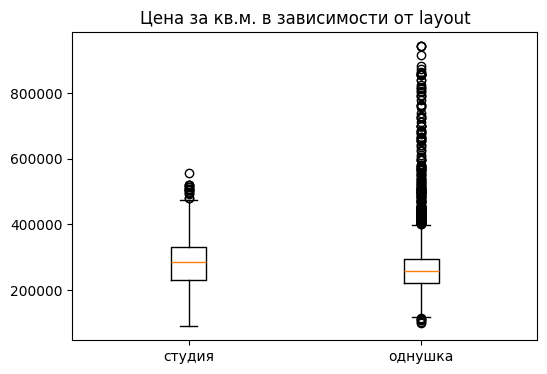

In [ ]:
boxplot('layout')

In [ ]:
df.groupby('layout')['price_per_m2'].describe().round(2).reset_index()

,layout,count,mean,std,min,25%,50%,75%,max
0,однушка,4327.0,270721.48,88435.07,100000.0,222492.00,256826.0,293434.50,942721.0
1,студия,1266.0,287803.49,72731.11,89450.0,231791.25,285779.5,329609.75,556000.0


In [ ]:
describe_prices('layout')

Описательные статистики для студия
Медина = 286 тыс.р.
Межквартильный интервал = 232-330 тыс.р.
Относительный размах IQR = 34: Интервал средний. Нормальная, естественная вариация данных.
Стандартное отклонение = 73 тыс.
Коэффициент вариации  = 25: Разброс заметен, но данные все еще однородные.
----------------------------------------------------------------------------------------------------
Описательные статистики для однушка
Медина = 257 тыс.р.
Межквартильный интервал = 222-293 тыс.р.
Относительный размах IQR = 28: Интервал средний. Нормальная, естественная вариация данных.
Стандартное отклонение = 88 тыс.
Коэффициент вариации  = 34: Данные неоднородны. В выборке наблюдается сильный разброс, могут присутствовать аномалии или скрытые подгруппы.
----------------------------------------------------------------------------------------------------


**Гипотезы:**

**h0:** Цена за кв.м. у студий и однушек **не различается систематически**, то есть случайно выбранная студия с равной вероятностью окажется дешевле или дороже случайно выбранной однушки.

**h1:** Цена за кв.м. **систематически различается**, одна из групп чаще оказывается дороже.

In [ ]:
brunnermunzel_test('layout');

Статистика Бруннера-Мунцеля: -10.7747, p-value (two-sided): 0.000000
----------------------------------------------------------------------------------------------------
Так как p-value < 0.05, нулевая гипотеза h0 отвергается. Различие статистически значимо.
----------------------------------------------------------------------------------------------------
Статистика W:-10.7747 отрицательная, что соответствует
P = P(студия < однушка) + 1/2*P(студия = однушка) < 0.5.)
Распределение цен группы студия смещено в сторону больших значений.


Проеврим есть ли корреляция между **ценой за кв.м. и площадью квартиры.**

**Гипотезы:**

**h0:** Между площадью квартиры и ценой за кв.м. **нет корреляции.**

**h1:** Между площадью квартиры и ценой за кв.м. **есть корреляция.**

In [ ]:
pearson('area', 'price_per_m2')

Коэффициент Пирсона = 0.1980, p-value = 0.0000
p < 0.05, тогда h0 отвергается. Различие статистически значимо.


In [ ]:
spearman('area', 'price_per_m2')

Коэффициент Спирмена = -0.0338, p-value = 0.0116
p < 0.05, тогда h0 отвергается. Различие статистически значимо.


Отрицательный коэффициент Спирмена, показывает, что с ростом площади удельная стоимость квадратного метра незначительно снижается. Однако смещение коэффициента Пирсона в положительную сторону может быть обусловлено наличием в выборке премиум-сегмента. Уберем премиум и оценим корреляцию.

In [ ]:
pearson('area', 'price_per_m2', df=df[df['is_premium']==False])

Коэффициент Пирсона = -0.0391, p-value = 0.0047
p < 0.05, тогда h0 отвергается. Различие статистически значимо.


In [ ]:
spearman('area', 'price_per_m2', df=df[df['is_premium']==False])

Коэффициент Спирмена = -0.0768, p-value = 0.0000
p < 0.05, тогда h0 отвергается. Различие статистически значимо.


Для массового рынка жилья оба теста показали статистически значимую, но **слабую отрицательную взаимосвязь** между общей площадью квартиры и стоимостью квадратного метра.

##**Тип жилья: новостройка vs вторичка**

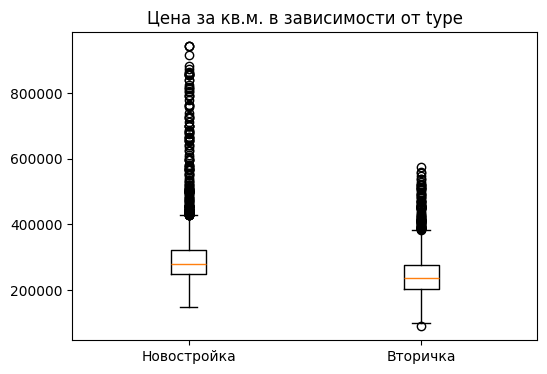

In [ ]:
boxplot('type')

In [ ]:
describe_prices('type')

Описательные статистики для Вторичка
Медина = 236 тыс.р.
Межквартильный интервал = 204-276 тыс.р.
Относительный размах IQR = 31: Интервал средний. Нормальная, естественная вариация данных.
Стандартное отклонение = 66 тыс.
Коэффициент вариации  = 28: Разброс заметен, но данные все еще однородные.
----------------------------------------------------------------------------------------------------
Описательные статистики для Новостройка
Медина = 279 тыс.р.
Межквартильный интервал = 249-321 тыс.р.
Относительный размах IQR = 26: Интервал средний. Нормальная, естественная вариация данных.
Стандартное отклонение = 92 тыс.
Коэффициент вариации  = 33: Разброс заметен, но данные все еще однородные.
----------------------------------------------------------------------------------------------------


**Гипотезы:**

**h0:** Цена за кв.м. у объектов в новостройке и вторичке **не различается систематически**, то есть случайно выбранная квартира из новостройки с равной вероятностью окажется дешевле или дороже случайно выбранной из вторички.

**h1:** Цена за кв.м. **систематически различается**, одна из групп чаще оказывается дороже.

In [ ]:
brunnermunzel_test('type');

Статистика Бруннера-Мунцеля: 30.2058, p-value (two-sided): 0.000000
----------------------------------------------------------------------------------------------------
Так как p-value < 0.05, нулевая гипотеза h0 отвергается. Различие статистически значимо.
----------------------------------------------------------------------------------------------------
Статистика W = 30.2058 положительная, что соответствует
P = P(Вторичка < Новостройка) + 1/2*P(Вторичка = Новостройка) > 0.5.)
Распределение цен группы «Новостройка» смещено в сторону больших значений.


Проверим, есть ли корреляция между **возрастом дома и его ценой за кв.м.**

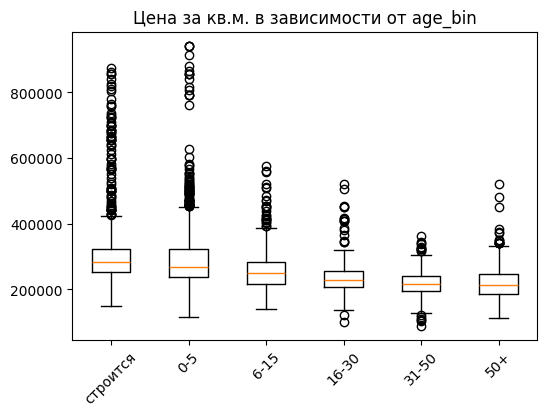

In [ ]:
boxplot('age_bin', df=df[~(df['age_bin']=='неизвестно')])

**Гипотезы:**

**h0:** Между возрастом дома и ценой за кв.м. **нет корреляции.**

**h1:** Между возрастом дома и ценой за кв.м. **есть корреляция.**

In [ ]:
spearman('age', 'price_per_m2', df=df[~(df['age_bin']=='неизвестно')])

Коэффициент Спирмена = -0.4271, p-value = 0.0000
p < 0.05, тогда h0 отвергается. Различие статистически значимо.


In [ ]:
pearson('age', 'price_per_m2', df=df[~(df['age_bin']=='неизвестно')])

Коэффициент Пирсона = -0.3392, p-value = 0.0000
p < 0.05, тогда h0 отвергается. Различие статистически значимо.


Поскольку коэффициент Спирмена по модулю заметно выше Пирсона (0.427 и 0.339), можно сделать вывод, что чистой линейной зависимости здесь нет. Присутствует отрицательная монотонная нелинейная связь умеренной силы.

##**Район**

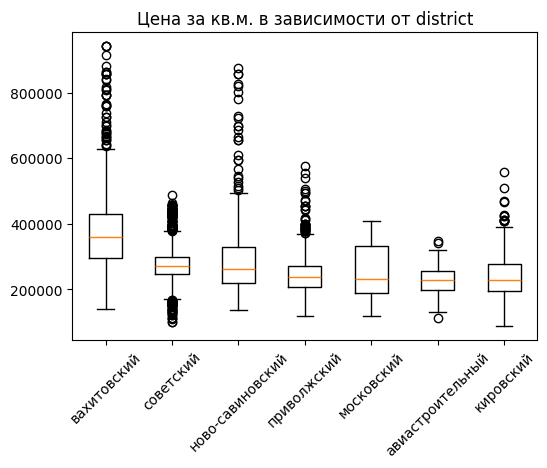

In [ ]:
boxplot('district')

In [ ]:
describe_prices('district')

Описательные статистики для приволжский
Медина = 238 тыс.р.
Межквартильный интервал = 207-272 тыс.р.
Относительный размах IQR = 28: Интервал средний. Нормальная, естественная вариация данных.
Стандартное отклонение = 56 тыс.
Коэффициент вариации  = 23: Разброс заметен, но данные все еще однородные.
----------------------------------------------------------------------------------------------------
Описательные статистики для советский
Медина = 272 тыс.р.
Межквартильный интервал = 248-300 тыс.р.
Относительный размах IQR = 19: Интервал средний. Нормальная, естественная вариация данных.
Стандартное отклонение = 51 тыс.
Коэффициент вариации  = 19: Разброс заметен, но данные все еще однородные.
----------------------------------------------------------------------------------------------------
Описательные статистики для кировский
Медина = 227 тыс.р.
Межквартильный интервал = 195-277 тыс.р.
Относительный размах IQR = 36: Интервал средний. Нормальная, естественная вариация данных.
Стандартно

**Гипотезы:**

**h0:** Медианная цена за квадратный метр **не зависит от района**.

**h1:** Хотя бы в одном районе типичная **цена отличается** от остальных.

In [ ]:
district = df[['district', 'price_per_m2']].groupby("district")
groups = [j['price_per_m2'].values for i, j in district]
stat, p, med, table = median_test(*groups)

print(f"grand median = {med:.2f}, p = {p:.4f}")

grand median = 260589.50, p = 0.0000


p < 0.05, тогда **h0 отвергается**. Мединная цена за кв.м. зависит от района.

Проведем попарный тест Брунера-Мунцеля для районов.

In [ ]:
brunnermunzel_test_pairwise('district')

     Категория 1      Категория 2        W  p_value  p_value_holm           significant                       Медиана цены за кв.м. Большие значения
     приволжский        советский  20.2047 0.000000      0.000000 статистически значимо             приволжский=238 и советский=272        советский
     приволжский        кировский  -2.4693 0.013753      0.013753 статистически значимо             приволжский=238 и кировский=227      приволжский
     приволжский авиастроительный  -4.2727 0.000023      0.000046 статистически значимо      приволжский=238 и авиастроительный=230      приволжский
     приволжский ново-савиновский   8.2135 0.000000      0.000000 статистически значимо      приволжский=238 и ново-савиновский=261 ново-савиновский
     приволжский      вахитовский  41.8563 0.000000      0.000000 статистически значимо           приволжский=238 и вахитовский=361      вахитовский
       советский        кировский -13.2102 0.000000      0.000000 статистически значимо               сове

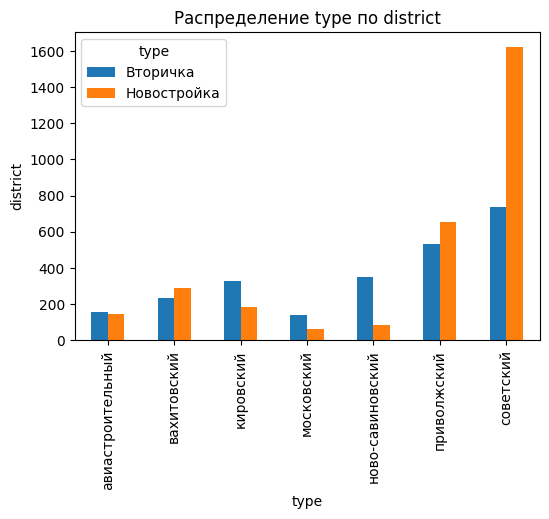

In [ ]:
plotbar('type', 'district')

По графику видно, что районы сильно различаются по структуре вторичка/новостройка. Это может влиять на сравнение цен.

**Гипотезы:**

**h0:** Доля новостроек **одинакова во всех районах** (тип жилья и район независимы).

**h1:** Доля новостроек **различается хотя бы в одном районе.**

In [ ]:
chi2('type', 'district')

Статистика Хи-квадрат = 537.032, p-value = 0.00000
p < 0.05, тогда h0 отвергается. Различие статистически значимо.


##**Метро**

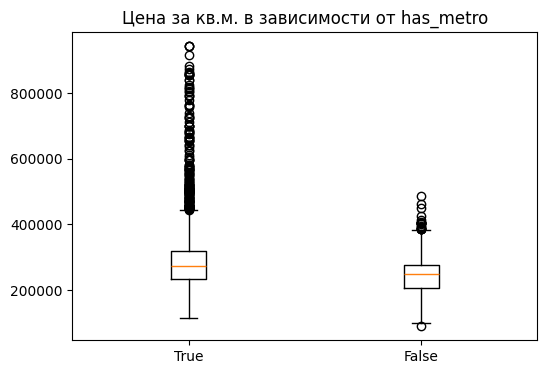

In [ ]:
boxplot('has_metro')

In [ ]:
describe_prices('has_metro')

Описательные статистики для True
Медина = 272 тыс.р.
Межквартильный интервал = 234-319 тыс.р.
Относительный размах IQR = 31: Интервал средний. Нормальная, естественная вариация данных.
Стандартное отклонение = 94 тыс.
Коэффициент вариации  = 35: Данные неоднородны. В выборке наблюдается сильный разброс, могут присутствовать аномалии или скрытые подгруппы.
----------------------------------------------------------------------------------------------------
Описательные статистики для False
Медина = 248 тыс.р.
Межквартильный интервал = 206-277 тыс.р.
Относительный размах IQR = 29: Интервал средний. Нормальная, естественная вариация данных.
Стандартное отклонение = 54 тыс.
Коэффициент вариации  = 22: Разброс заметен, но данные все еще однородные.
----------------------------------------------------------------------------------------------------


**Гипотезы:**

**h0:** Цена за кв.м. у объектов с метро и без **не различается систематически**.

**h1:** Цена за кв.м. **систематически различается**, одна из групп чаще оказывается дороже.

In [ ]:
brunnermunzel_test('has_metro');

Статистика Бруннера-Мунцеля: -19.9654, p-value (two-sided): 0.000000
----------------------------------------------------------------------------------------------------
Так как p-value < 0.05, нулевая гипотеза h0 отвергается. Различие статистически значимо.
----------------------------------------------------------------------------------------------------
Статистика W:-19.9654 отрицательная, что соответствует
P = P(True < False) + 1/2*P(True = False) < 0.5.)
Распределение цен группы True смещено в сторону больших значений.


Проверим есть ли корреляция между **временем до метро и ценой за кв.м.**

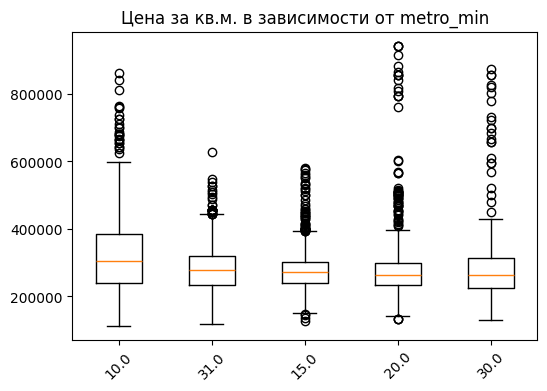

In [ ]:
boxplot('metro_min', df=df[df['metro_min']>=10])

**Гипотезы:**

**h0:** Между временем до метро и ценой за кв.м. **нет корреляции.**

**h1:** Между временем до метро и ценой за кв.м. **есть корреляция.**

In [ ]:
pearson('metro_min', 'price_per_m2')

Коэффициент Пирсона = -0.0919, p-value = 0.0000
p < 0.05, тогда h0 отвергается. Различие статистически значимо.


In [ ]:
spearman('metro_min', 'price_per_m2')

Коэффициент Спирмена = -0.0527, p-value = 0.0013
p < 0.05, тогда h0 отвергается. Различие статистически значимо.


Между временем до метро и ценой за квадратный метр присутствет статистически значимая, но крайне **слабая отрицательная линейная взаимосвязь.**

##**ЖК**

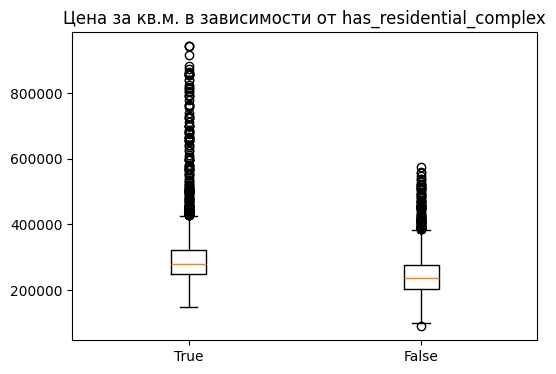

In [ ]:
boxplot('has_residential_complex')

In [ ]:
describe_prices('has_residential_complex')

Описательные статистики для False
Медина = 236 тыс.р.
Межквартильный интервал = 204-276 тыс.р.
Относительный размах IQR = 31: Интервал средний. Нормальная, естественная вариация данных.
Стандартное отклонение = 66 тыс.
Коэффициент вариации  = 28: Разброс заметен, но данные все еще однородные.
----------------------------------------------------------------------------------------------------
Описательные статистики для True
Медина = 280 тыс.р.
Межквартильный интервал = 249-321 тыс.р.
Относительный размах IQR = 25: Интервал средний. Нормальная, естественная вариация данных.
Стандартное отклонение = 92 тыс.
Коэффициент вариации  = 33: Разброс заметен, но данные все еще однородные.
----------------------------------------------------------------------------------------------------


**Гипотезы:**

**h0:** Цена за кв.м. у объектов с ЖК и без **не различается систематически**.

**h1:** Цена за кв.м. **систематически различается**, одна из групп чаще оказывается дороже.

In [ ]:
brunnermunzel_test('has_residential_complex');

Статистика Бруннера-Мунцеля: 30.5195, p-value (two-sided): 0.000000
----------------------------------------------------------------------------------------------------
Так как p-value < 0.05, нулевая гипотеза h0 отвергается. Различие статистически значимо.
----------------------------------------------------------------------------------------------------
Статистика W = 30.5195 положительная, что соответствует
P = P(False < True) + 1/2*P(False = True) > 0.5.)
Распределение цен группы «True» смещено в сторону больших значений.


Проверим есть ли зависимость между наличием ЖК и типом дома (вторичка/новостройка).

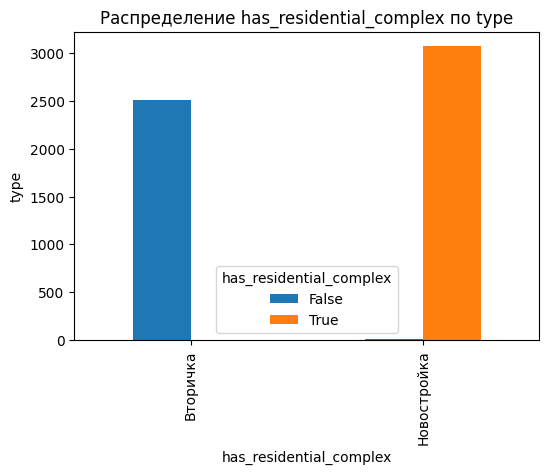

In [ ]:
plotbar('has_residential_complex', 'type')

**Гипотезы:**

**h0:** Наличие ЖК и тип дома **независимы.**

**h1:** Наличие ЖК и его тип **взаимосвязаны (зависимы)** друг от друга.

In [ ]:
chi2('has_residential_complex', 'type')

Статистика Хи-квадрат = 537.032, p-value = 0.00000
p < 0.05, тогда h0 отвергается. Различие статистически значимо.


##**Этаж: крайние этажи vs средние**

In [ ]:
df_floors = df.copy()
df_floors['floor_out_middle'] = 'средний'
mask = (df_floors['floor'] == 1) | (df_floors['floor'] == df_floors['total_floors'])
df_floors.loc[mask, 'floor_out_middle'] = 'первый или последний'

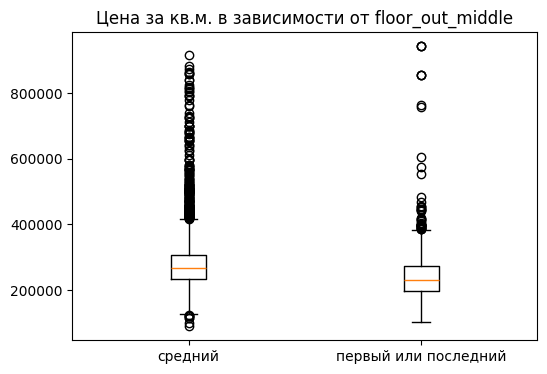

In [ ]:
boxplot('floor_out_middle', df=df_floors)

In [ ]:
describe_prices('floor_out_middle', df=df_floors)

Описательные статистики для средний
Медина = 266 тыс.р.
Межквартильный интервал = 233-307 тыс.р.
Относительный размах IQR = 28: Интервал средний. Нормальная, естественная вариация данных.
Стандартное отклонение = 84 тыс.
Коэффициент вариации  = 31: Разброс заметен, но данные все еще однородные.
----------------------------------------------------------------------------------------------------
Описательные статистики для первый или последний
Медина = 231 тыс.р.
Межквартильный интервал = 197-272 тыс.р.
Относительный размах IQR = 33: Интервал средний. Нормальная, естественная вариация данных.
Стандартное отклонение = 87 тыс.
Коэффициент вариации  = 38: Данные неоднородны. В выборке наблюдается сильный разброс, могут присутствовать аномалии или скрытые подгруппы.
----------------------------------------------------------------------------------------------------


**Гипотезы:**

**h0:** Цена за кв.м. у объектов на средних и крайних этажах **не различается систематически**.

**h1:** Цена за кв.м. **систематически различается**, одна из групп чаще оказывается дороже.

In [ ]:
brunnermunzel_test('floor_out_middle', df=df_floors);

Статистика Бруннера-Мунцеля: -16.1121, p-value (two-sided): 0.000000
----------------------------------------------------------------------------------------------------
Так как p-value < 0.05, нулевая гипотеза h0 отвергается. Различие статистически значимо.
----------------------------------------------------------------------------------------------------
Статистика W:-16.1121 отрицательная, что соответствует
P = P(средний < первый или последний) + 1/2*P(средний = первый или последний) < 0.5.)
Распределение цен группы средний смещено в сторону больших значений.


Проверим есть ли корреляция между **этажностью дома и ценой за кв.м.**

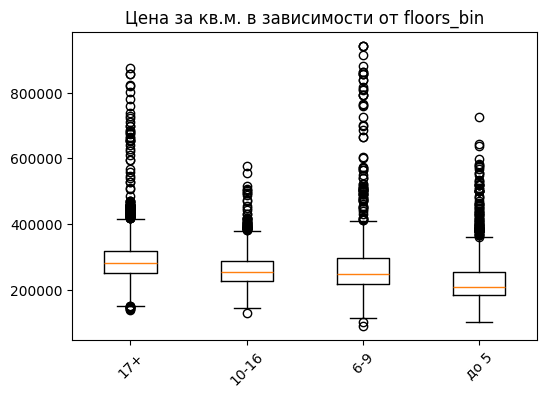

In [ ]:
boxplot('floors_bin', 'price_per_m2')

**Гипотезы:**

**h0:** Между этажностью дома и ценой за кв.м. **нет корреляции.**

**h1:** Между этажностью дома и ценой за кв.м. **есть корреляция.**

In [ ]:
pearson('total_floors', 'price_per_m2')

Коэффициент Пирсона = 0.2035, p-value = 0.0000
p < 0.05, тогда h0 отвергается. Различие статистически значимо.


In [ ]:
spearman('total_floors', 'price_per_m2')

Коэффициент Спирмена = 0.3424, p-value = 0.0000
p < 0.05, тогда h0 отвергается. Различие статистически значимо.


Между этажностью дома и ценой за квадратный метр присутствует статистически значимая **положительная связь умеренной силы.**

Проверим есть ли зависимость между этажностью и типом дома (вторичка/новостройка).

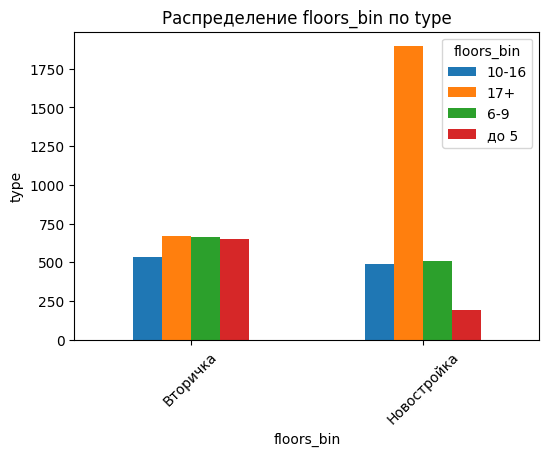

In [ ]:
plotbar('floors_bin', 'type')

**Гипотезы:**

**h0:** Этажность и тип дома **независимы.**

**h1:** Этажность дома и его тип **взаимосвязаны (зависимы)** друг от друга.

In [ ]:
chi2('floors_bin', 'type')

Статистика Хи-квадрат = 537.032, p-value = 0.00000
p < 0.05, тогда h0 отвергается. Различие статистически значимо.


##**Премиум сегмент: новостройка vs вторичка**

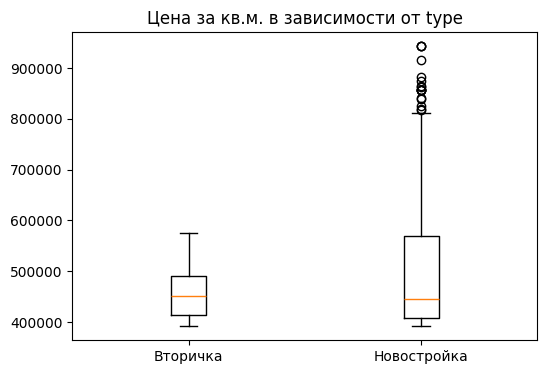

In [ ]:
df_premium = df[df['is_premium']]
boxplot(x='type', df=df_premium)

In [ ]:
describe_prices('type', df=df_premium)

Описательные статистики для Новостройка
Медина = 445 тыс.р.
Межквартильный интервал = 408-570 тыс.р.
Относительный размах IQR = 36: Интервал средний. Нормальная, естественная вариация данных.
Стандартное отклонение = 142 тыс.
Коэффициент вариации  = 32: Разброс заметен, но данные все еще однородные.
----------------------------------------------------------------------------------------------------
Описательные статистики для Вторичка
Медина = 452 тыс.р.
Межквартильный интервал = 414-491 тыс.р.
Относительный размах IQR = 17: Интервал средний. Нормальная, естественная вариация данных.
Стандартное отклонение = 47 тыс.
Коэффициент вариации  = 10: Разброс заметен, но данные все еще однородные.
----------------------------------------------------------------------------------------------------


**Гипотезы:**

**h0:** Цена за кв.м. у премиум-объектов в новостройке и вторичке **не различается систематически**.

**h1:** Цена за кв.м. **систематически различается**, одна из групп чаще оказывается дороже.

In [ ]:
brunnermunzel_test('type', df=df_premium);

Статистика Бруннера-Мунцеля: -1.1979, p-value (two-sided): 0.232011
----------------------------------------------------------------------------------------------------
Так как p-value >= 0.05, нулевая гипотеза h0 НЕ отвергается. Различие статистически незначимо.


Проверим есть ли зависимость между **сегментом недвижимости (премиум/массовый) и типом дома (вторичка/новостройка).**

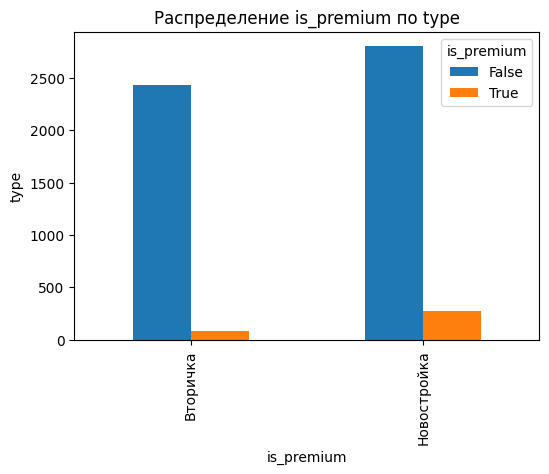

In [ ]:
plotbar('is_premium', 'type')

**Гипотезы:**

**h0:** Сегмент и тип дома **независимы.**

**h1:** Сегмент и его тип **взаимосвязаны (зависимы)** друг от друга.

In [ ]:
chi2('is_premium', 'type')

Статистика Хи-квадрат = 537.032, p-value = 0.00000
p < 0.05, тогда h0 отвергается. Различие статистически значимо.


##**Результаты**


**Сравнение групп (тест Бруннера-Мунцеля / медианный тест)**

- h0: Группы не отличаются.
- h1: Группы систематически различаются.

1) Планировка (студии vs однушки). h0 отвергается, p < 0.05. Студии дороже.

2) Тип жилья (новостройка vs вторичка). h0 отвергается, p < 0.05. Новостройки дороже.

3) Наличие метро (да vs нет). h0 отвергается, p < 0.05. С метро дороже.

4) Наличие ЖК (да vs нет). h0 отвергается, p < 0.05. С ЖК дороже.

5) Этаж (средний vs первый/последний). h0 отвергается, p < 0.05. Средние этажи дороже.

6) Премиум-сегмент (новостройка vs вторичка). h0 не отвергается, p = 0.232. Разницы нет.

7) Район. h0: медианы цены во всех районах равны. Отвергается, p < 0.05, медианы различаются. Попарный тест: значимые различия почти во всех парах. Самый дорогой – Вахитовский, самые дешевые – Авиастроительный и Кировский.

**Критерий Хи-квадрат**

- h0: Признаки независимы.
- h1: Признаки зависимы.

1) Тип жилья и район. h0 отвергается, p < 0.05. Признаки связаны.

2) Наличие ЖК и тип дома. h0 отвергается, p < 0.05. Признаки связаны.

3) Этажность и тип дома. h0 отвергается, p < 0.05. Признаки связаны.

4) Сегмент (премиум/массовый) и тип дома. h0 отвергается, p < 0.05. Признаки связаны.

**Корреляции (Пирсон и Спирмен)**

- h0: Корреляции нет.
- h1: Корреляция есть.

1) Площадь и цена за кв.м. (массовый рынок). h0 отвергается, p < 0.05, но связь очень слабая отрицательная (-0.039 / -0.077).

2) Возраст дома и цена за кв.м. h0 отвергается, p < 0.05. Отрицательная связь умеренной силы (-0.339 / -0.427): чем старше дом, тем ниже цена.

3) Время до метро и цена за кв.м. h0 отвергается, p < 0.05, но связь крайне слабая отрицательная (-0.092 / -0.053).

4) Этажность дома и цена за кв.м. h0 отвергается, p < 0.05. Положительная связь умеренной силы (0.204 / 0.342): чем выше дом, тем выше цена.